In [23]:
# ============================================================
# 1. Import Libraries
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from scipy.stats import loguniform

from skorch import NeuralNetClassifier

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


torch.manual_seed(42)
np.random.seed(42)

print("Libraries imported successfully.")
print(f"PyTorch version: {torch.__version__}")

Libraries imported successfully.
PyTorch version: 2.14.1+cpu


In [24]:
# ============================================================
# 2. Read CSV Dataset & Clean Missing Values / Columns
# ============================================================
file_path = "heart_disease_uci.csv"

df = pd.read_csv(file_path, na_values='?')

if 'id' in df.columns:
    df = df.drop(columns=['id'])

if 'dataset' in df.columns:
    df = df.drop(columns=['dataset'])
    print("Column 'dataset' removed successfully.")

print("Dataset loaded successfully.")
print("Dataset shape before cleaning:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

Column 'dataset' removed successfully.
Dataset loaded successfully.
Dataset shape before cleaning: (920, 14)

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [25]:
# ============================================================
# 3. Data Quality & Correct Categorical Encoding
# ============================================================
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

bool_cols = df.select_dtypes(include=['bool']).columns
for col in bool_cols:
    df[col] = df[col].astype(float)

categorical_cols = df.select_dtypes(include=['object', 'string', 'category']).columns

for col in categorical_cols:
    df[col] = df[col].astype('category').cat.codes
    df[col] = df[col].replace(-1, np.nan)

print("Actual missing values per column:")
display(df.isnull().sum())

print("\nTotal actual missing values:", df.isnull().sum().sum())

df = df.dropna().reset_index(drop=True)

duplicate_count = df.duplicated().sum()
print("\nNumber of duplicate rows:", duplicate_count)
if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed.")

print("\nFinal dataset shape after cleaning:", df.shape)
display(df.describe().T)

Actual missing values per column:


age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


Total actual missing values: 1759

Number of duplicate rows: 0

Final dataset shape after cleaning: (299, 14)


,count,mean,std,min,25%,50%,75%,max
age,299.0,54.521739,9.030264,29.0,48.0,56.0,61.0,77.0
sex,299.0,0.678930,0.467670,0.0,0.0,1.0,1.0,1.0
cp,299.0,0.949833,1.033414,0.0,0.0,1.0,2.0,3.0
trestbps,299.0,131.715719,17.747751,94.0,120.0,130.0,140.0,200.0
chol,299.0,246.785953,52.532582,100.0,211.0,242.0,275.5,564.0
fbs,299.0,0.143813,0.351488,0.0,0.0,0.0,0.0,1.0
restecg,299.0,0.525084,0.526358,0.0,0.0,1.0,1.0,2.0
thalch,299.0,149.327759,23.121062,71.0,132.5,152.0,165.5,202.0
exang,299.0,0.331104,0.471399,0.0,0.0,0.0,1.0,1.0
oldpeak,299.0,1.058528,1.162769,0.0,0.0,0.8,1.6,6.2


Target distribution (num):


num
0    160
1     56
2     35
3     35
4     13
Name: count, dtype: int64


Target percentage (%):


num
0    53.51
1    18.73
2    11.71
3    11.71
4     4.35
Name: proportion, dtype: float64

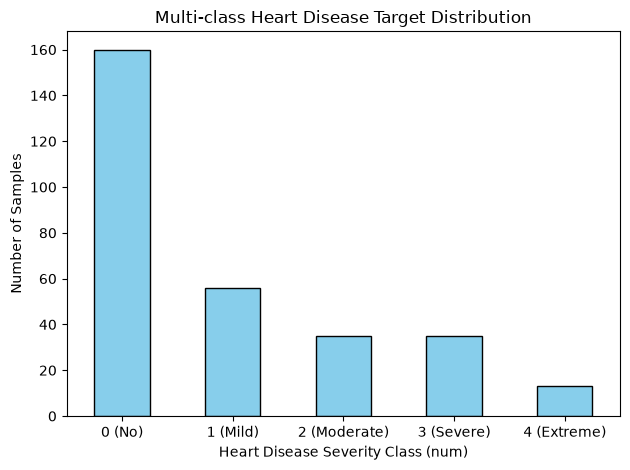

In [26]:
# ============================================================
# 4. Target Distribution (Multi-Class: 0 to 4)
# ============================================================
print("Target distribution (num):")
display(df["num"].value_counts().sort_index())

print("\nTarget percentage (%):")
display((df["num"].value_counts(normalize=True).sort_index() * 100).round(2))

df["num"].value_counts().sort_index().plot(kind="bar", color="skyblue", edgecolor="black")
plt.xlabel("Heart Disease Severity Class (num)")
plt.ylabel("Number of Samples")
plt.title("Multi-class Heart Disease Target Distribution")
plt.xticks(ticks=range(5), labels=["0 (No)", "1 (Mild)", "2 (Moderate)", "3 (Severe)", "4 (Extreme)"], rotation=0)
plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# 5. Prepare X and y
# ============================================================
X = df.drop(columns=["num"]).astype(np.float32)
y = df["num"].values.astype(np.int64)

feature_names = X.columns.tolist()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures list:")
for i, feature in enumerate(feature_names):
    print(f"{i}: {feature}")

X shape: (299, 13)
y shape: (299,)

Features list:
0: age
1: sex
2: cp
3: trestbps
4: chol
5: fbs
6: restecg
7: thalch
8: exang
9: oldpeak
10: slope
11: ca
12: thal


In [28]:
# ============================================================
# 6. Train/Test Split (Stratified Multi-class)
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (239, 13)
X_test shape : (60, 13)
y_train shape: (239,)
y_test shape : (60,)


In [29]:
# ============================================================
# 7. Define PyTorch Modules & skorch Pipelines
# ============================================================
input_dim = X_train.shape[1]
num_classes = len(np.unique(y))

class LinearClassifier(nn.Module):
    def __init__(self, input_dim=input_dim, num_classes=num_classes):
        super().__init__()
        self.fc = nn.Linear(input_dim, num_classes)
        
    def forward(self, x):
        return self.fc(x)

class StandardMLP(nn.Module):
    def __init__(self, input_dim=input_dim, num_classes=num_classes, hidden_dim1=64, hidden_dim2=32, dropout_rate=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim1),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim1, hidden_dim2),
            nn.ReLU(),
            nn.Linear(hidden_dim2, num_classes)
        )
        
    def forward(self, x):
        return self.net(x)

class DeepMLP(nn.Module):
    def __init__(self, input_dim=input_dim, num_classes=num_classes, hidden_dim1=128, hidden_dim2=64, hidden_dim3=32, dropout_rate1=0.3, dropout_rate2=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim1),
            nn.BatchNorm1d(hidden_dim1),
            nn.ReLU(),
            nn.Dropout(dropout_rate1),
            nn.Linear(hidden_dim1, hidden_dim2),
            nn.BatchNorm1d(hidden_dim2),
            nn.ReLU(),
            nn.Dropout(dropout_rate2),
            nn.Linear(hidden_dim2, hidden_dim3),
            nn.ReLU(),
            nn.Linear(hidden_dim3, num_classes)
        )
        
    def forward(self, x):
        return self.net(x)

models = {
    "Linear Model (Softmax Regression)": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("net", NeuralNetClassifier(
                module=LinearClassifier,
                criterion=nn.CrossEntropyLoss,
                optimizer=torch.optim.Adam,
                train_split=None,
                verbose=0
            ))
        ]),
        {
            "net__lr": loguniform(1e-4, 1e-1),
            "net__optimizer__weight_decay": loguniform(1e-6, 1e-2),
            "net__max_epochs": [30, 50, 100],
            "net__batch_size": [16, 32, 64]
        },
        10
    ),

    "Standard 2-Layer MLP": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("net", NeuralNetClassifier(
                module=StandardMLP,
                criterion=nn.CrossEntropyLoss,
                optimizer=torch.optim.Adam,
                train_split=None,
                verbose=0
            ))
        ]),
        {
            "net__module__hidden_dim1": [32, 64, 128],
            "net__module__hidden_dim2": [16, 32, 64],
            "net__module__dropout_rate": [0.1, 0.2, 0.3],
            "net__lr": loguniform(1e-4, 1e-1),
            "net__optimizer__weight_decay": loguniform(1e-6, 1e-2),
            "net__max_epochs": [50, 80, 120],
            "net__batch_size": [16, 32, 64]
        },
        15
    ),

    "Deep Regularized MLP": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("net", NeuralNetClassifier(
                module=DeepMLP,
                criterion=nn.CrossEntropyLoss,
                optimizer=torch.optim.Adam,
                train_split=None,
                verbose=0
            ))
        ]),
        {
            "net__module__hidden_dim1": [64, 128, 256],
            "net__module__hidden_dim2": [32, 64, 128],
            "net__module__hidden_dim3": [16, 32],
            "net__module__dropout_rate1": [0.2, 0.3, 0.4],
            "net__module__dropout_rate2": [0.1, 0.2, 0.3],
            "net__lr": loguniform(1e-4, 1e-1),
            "net__optimizer__weight_decay": loguniform(1e-6, 1e-2),
            "net__max_epochs": [60, 100, 150],
            "net__batch_size": [16, 32, 64]
        },
        15
    )
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
print("3-fold Stratified CV configured with skorch.")

3-fold Stratified CV configured with skorch.


In [30]:
# ============================================================
# 8. Fast RandomizedSearchCV Execution & Multi-class Evaluation
# ============================================================
trained_models = {}
results = []
best_parameters = {}
cv_scores = {}

for name, (model_pipeline, param_distributions, n_iter) in models.items():
    print("\n" + "=" * 70)
    print(f"Training PyTorch Model via skorch: {name}")
    print("=" * 70)

    search = RandomizedSearchCV(
        estimator=model_pipeline,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring="f1_weighted",
        cv=cv,
        n_jobs=-1,
        random_state=42,
        verbose=1,
        return_train_score=False
    )

    search.fit(X_train, y_train)

    best_estimator = search.best_estimator_
    trained_models[name] = best_estimator
    best_parameters[name] = search.best_params_
    cv_scores[name] = search.best_score_

    y_pred = best_estimator.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1_weighted = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results.append({
        "Model": name,
        "CV F1 (Weighted)": search.best_score_,
        "Test Accuracy": accuracy,
        "Test Precision (Weighted)": precision,
        "Test Recall (Weighted)": recall,
        "Test F1 (Weighted)": f1_weighted
    })  

    print("\nBest Parameters:")
    print(search.best_params_)
    print(f"CV F1 (Weighted)       : {search.best_score_:.4f}")
    print(f"Test Accuracy          : {accuracy:.4f}")
    print(f"Test Precision         : {precision:.4f}")
    print(f"Test Recall            : {recall:.4f}")
    print(f"Test F1 (Weighted)     : {f1_weighted:.4f}")


Training PyTorch Model via skorch: Linear Model (Softmax Regression)
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters:
{'net__batch_size': 64, 'net__lr': np.float64(0.002386418878005608), 'net__max_epochs': 30, 'net__optimizer__weight_decay': np.float64(0.00025378155082656634)}
CV F1 (Weighted)       : 0.5402
Test Accuracy          : 0.5000
Test Precision         : 0.4456
Test Recall            : 0.5000
Test F1 (Weighted)     : 0.4712

Training PyTorch Model via skorch: Standard 2-Layer MLP
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters:
{'net__batch_size': 64, 'net__lr': np.float64(0.024526126311336778), 'net__max_epochs': 120, 'net__module__dropout_rate': 0.3, 'net__module__hidden_dim1': 32, 'net__module__hidden_dim2': 16, 'net__optimizer__weight_decay': np.float64(4.2079886696066345e-06)}
CV F1 (Weighted)       : 0.5822
Test Accuracy          : 0.5333
Test Precision         : 0.4872
Test Recall            : 0.5333
Test F1 

FINAL MODEL COMPARISON TABLE


,Model,CV F1 (Weighted),Test Accuracy,Test Precision (Weighted),Test Recall (Weighted),Test F1 (Weighted)
0,Standard 2-Layer MLP,0.582211,0.533333,0.487222,0.533333,0.507981
1,Linear Model (Softmax Regression),0.540181,0.500000,0.445602,0.500000,0.471225
2,Deep Regularized MLP,0.563868,0.450000,0.411468,0.450000,0.429872


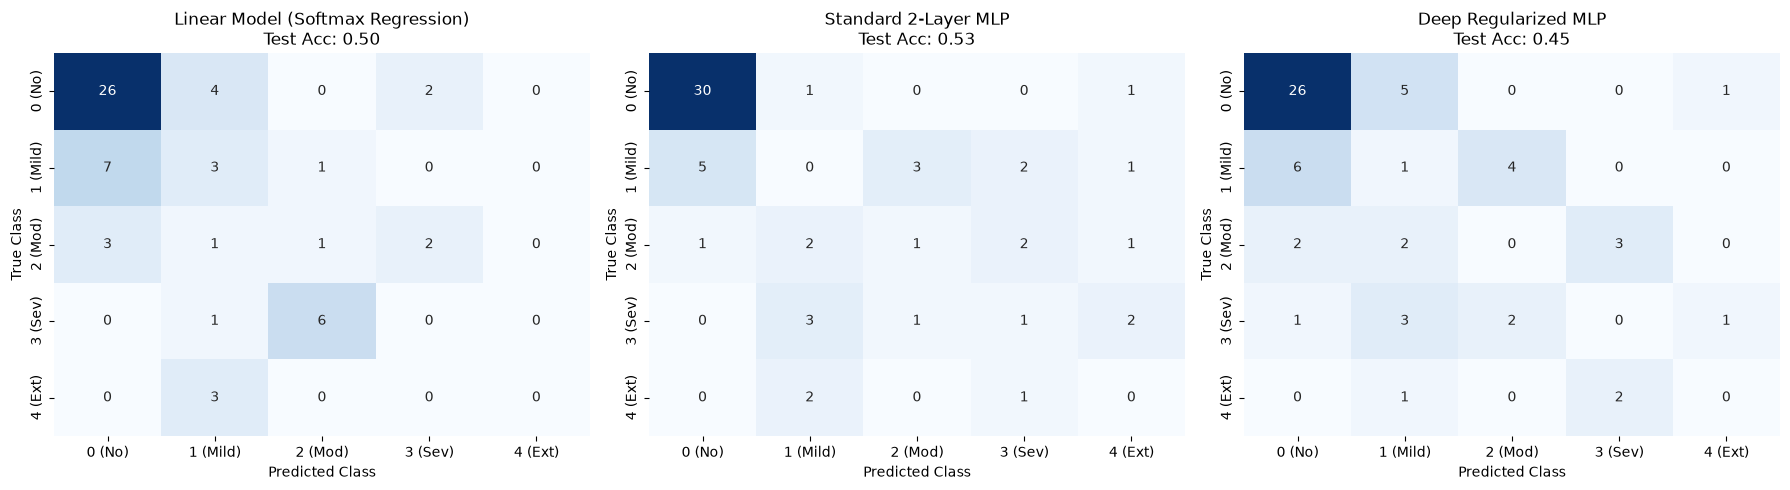

In [31]:
# ============================================================
# 9. Summary Table & 5x5 Confusion Matrix Visualization
# ============================================================
import seaborn as sns

df_results = pd.DataFrame(results)
print("=" * 80)
print("FINAL MODEL COMPARISON TABLE")
print("=" * 80)
display(df_results.sort_values(by="Test F1 (Weighted)", ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
class_names = ["0 (No)", "1 (Mild)", "2 (Mod)", "3 (Sev)", "4 (Ext)"]

for idx, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=class_names, yticklabels=class_names, cbar=False)
    axes[idx].set_title(f"{name}\nTest Acc: {accuracy_score(y_test, y_pred):.2f}")
    axes[idx].set_xlabel("Predicted Class")
    axes[idx].set_ylabel("True Class")

plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# 10. Detailed Classification Report for Best Model
# ============================================================
best_model_name = df_results.sort_values(by="Test F1 (Weighted)", ascending=False).iloc[0]["Model"]
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test)

print("=" * 80)
print(f"DETAILED CLASSIFICATION REPORT FOR BEST MODEL: {best_model_name}")
print("=" * 80)
print(classification_report(y_test, y_pred_best, target_names=class_names, zero_division=0))

DETAILED CLASSIFICATION REPORT FOR BEST MODEL: Standard 2-Layer MLP
              precision    recall  f1-score   support

      0 (No)       0.83      0.94      0.88        32
    1 (Mild)       0.00      0.00      0.00        11
     2 (Mod)       0.20      0.14      0.17         7
     3 (Sev)       0.17      0.14      0.15         7
     4 (Ext)       0.00      0.00      0.00         3

    accuracy                           0.53        60
   macro avg       0.24      0.24      0.24        60
weighted avg       0.49      0.53      0.51        60



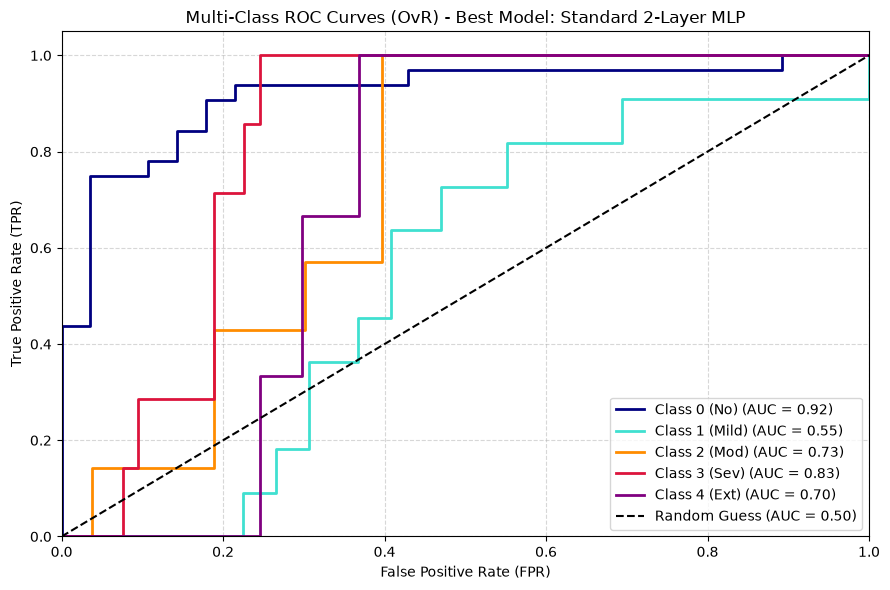

In [33]:
# ============================================================
# 11. Multi-class ROC Curves & ROC-AUC Scores (One-vs-Rest)
# ============================================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4])
n_classes = y_test_bin.shape[1]

y_score = best_model.predict_proba(X_test)

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(9, 6))
colors = ['navy', 'turquoise', 'darkorange', 'crimson', 'purple']

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title(f'Multi-Class ROC Curves (OvR) - Best Model: {best_model_name}')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()